In [1]:
!pip install pandas numpy matplotlib seaborn plotly

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

from plotly.subplots import make_subplots
from google.colab import files

In [3]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset Imported Successfully!")
display(df.head())

Saving movie_entertainment_dataset_150.csv to movie_entertainment_dataset_150.csv
Dataset Imported Successfully!


,Movie ID,Movie Title,Budget (USD millions),Revenue (USD millions),Rating (/10),Genre,Release Date
0,M001,Golden Journey,167,369.8,5.8,Crime,10-Aug-2018
1,M002,distant Galaxy,134,141.5,8.0,Adventure,16-Jan-2022
2,M003,distant Legacy,133,135.5,6.3,Romance,03-Apr-2021
3,M004,Dark Code,228,73.2,6.3,Animation,18-Mar-2022
4,M005,Last Frontier,124,112.2,8.3,Action,28-Jan-2015


In [4]:
# Convert Release Date into datetime format
df['Release Date'] = pd.to_datetime(
    df['Release Date'],
    format='%d-%b-%Y',
    errors='coerce'
)

# Create Release Year column
df['Release Year'] = df['Release Date'].dt.year

print("Dataset Preparation Completed!")

Dataset Preparation Completed!


In [5]:
print("Number of Rows and Columns:")
print(df.shape)

print("\nTotal Records:", df.shape[0])
print("Total Columns:", df.shape[1])

Number of Rows and Columns:
(150, 8)

Total Records: 150
Total Columns: 8


In [6]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Movie ID                150 non-null    object        
 1   Movie Title             150 non-null    object        
 2   Budget (USD millions)   150 non-null    int64         
 3   Revenue (USD millions)  150 non-null    float64       
 4   Rating (/10)            150 non-null    float64       
 5   Genre                   150 non-null    object        
 6   Release Date            150 non-null    datetime64[ns]
 7   Release Year            150 non-null    int32         
dtypes: datetime64[ns](1), float64(2), int32(1), int64(1), object(3)
memory usage: 8.9+ KB


In [7]:
print("Statistical Description:")
display(df.describe())

Statistical Description:


,Budget (USD millions),Revenue (USD millions),Rating (/10),Release Date,Release Year
count,150.000000,150.000000,150.000000,150,150.000000
mean,120.246667,213.437333,6.875333,2020-08-20 02:24:00,2020.173333
min,5.000000,4.000000,4.100000,2015-01-17 00:00:00,2015.000000
25%,51.500000,62.225000,5.625000,2018-02-05 06:00:00,2018.000000
50%,122.500000,115.100000,7.150000,2020-10-27 12:00:00,2020.000000
75%,179.000000,294.575000,8.000000,2023-06-07 12:00:00,2023.000000
max,249.000000,989.500000,9.100000,2025-12-21 00:00:00,2025.000000
std,73.030373,218.445681,1.466170,NaN,3.210191


In [8]:
print("Genre Distribution:")
print(df['Genre'].value_counts())

print("\nMovie Release Year Distribution:")
print(df['Release Year'].value_counts().sort_index())

Genre Distribution:
Genre
Action             19
Horror             17
Romance            15
Animation          14
Documentary        13
Fantasy            12
Comedy             12
Thriller           11
Drama              11
Science Fiction    10
Crime               8
Adventure           8
Name: count, dtype: int64

Movie Release Year Distribution:
Release Year
2015    14
2016    15
2017     6
2018    16
2019    12
2020    18
2021    10
2022    15
2023    14
2024    14
2025    16
Name: count, dtype: int64


In [9]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Movie ID                  0
Movie Title               0
Budget (USD millions)     0
Revenue (USD millions)    0
Rating (/10)              0
Genre                     0
Release Date              0
Release Year              0
dtype: int64

Duplicate Records:
0


In [10]:
correlation = df[
    ['Budget (USD millions)', 'Revenue (USD millions)', 'Rating (/10)']
].corr()

print("Correlation Matrix:")
display(correlation)

budget_revenue_corr = correlation.loc[
    'Budget (USD millions)',
    'Revenue (USD millions)'
]

print("\nBudget vs Revenue Correlation:", round(budget_revenue_corr, 3))

Correlation Matrix:


,Budget (USD millions),Revenue (USD millions),Rating (/10)
Budget (USD millions),1.000000,0.566306,-0.073008
Revenue (USD millions),0.566306,1.000000,-0.097844
Rating (/10),-0.073008,-0.097844,1.000000



Budget vs Revenue Correlation: 0.566


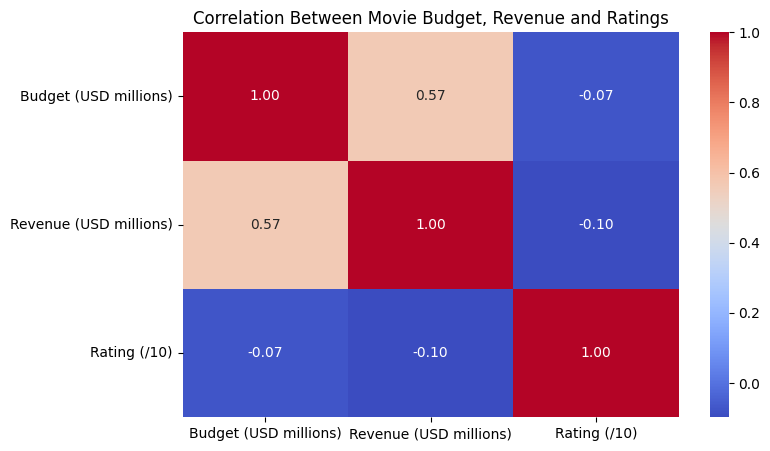

In [11]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Movie Budget, Revenue and Ratings")
plt.show()

In [12]:
genre_analysis = df.groupby('Genre').agg({
    'Budget (USD millions)': 'mean',
    'Revenue (USD millions)': 'mean',
    'Rating (/10)': 'mean',
    'Movie ID': 'count'
}).rename(columns={
    'Movie ID': 'Total Movies'
})

print("Genre-wise Analysis:")
display(genre_analysis.round(2))

Genre-wise Analysis:


,Budget (USD millions),Revenue (USD millions),Rating (/10),Total Movies
Genre,,,,
Action,126.42,143.79,7.08,19
Adventure,127.25,290.35,6.46,8
Animation,140.93,271.66,6.46,14
Comedy,119.50,235.75,6.87,12
Crime,140.88,308.56,7.58,8
Documentary,104.00,167.95,6.32,13
Drama,85.36,156.23,6.46,11
Fantasy,128.33,218.10,7.15,12
Horror,96.00,179.07,7.15,17


In [13]:
top_genre = genre_analysis['Revenue (USD millions)'].idxmax()

print("Genre with Highest Average Revenue:", top_genre)

print(
    "Average Revenue:",
    round(
        genre_analysis.loc[top_genre, 'Revenue (USD millions)'],
        2
    ),
    "Million USD"
)

Genre with Highest Average Revenue: Romance
Average Revenue: 313.65 Million USD


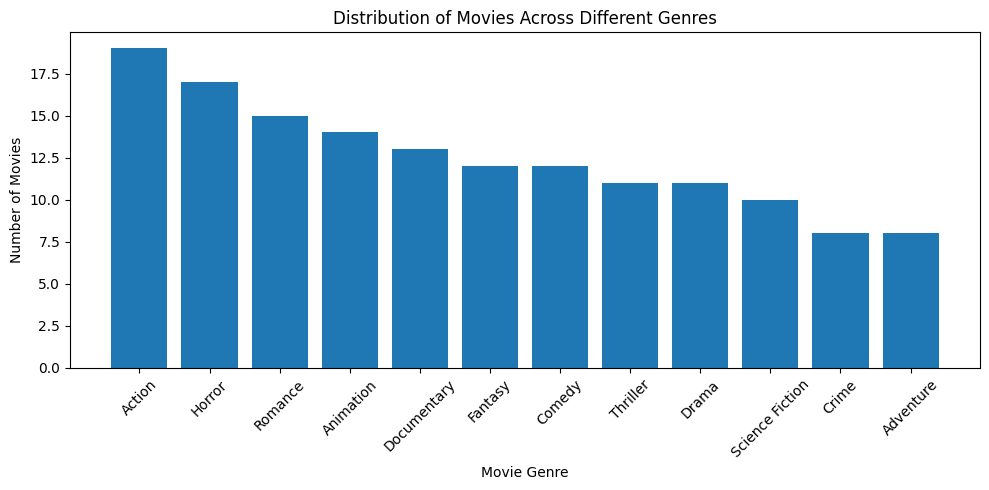

In [14]:
plt.figure(figsize=(10, 5))

genre_counts = df['Genre'].value_counts()

plt.bar(
    genre_counts.index,
    genre_counts.values
)

plt.title("Distribution of Movies Across Different Genres")
plt.xlabel("Movie Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

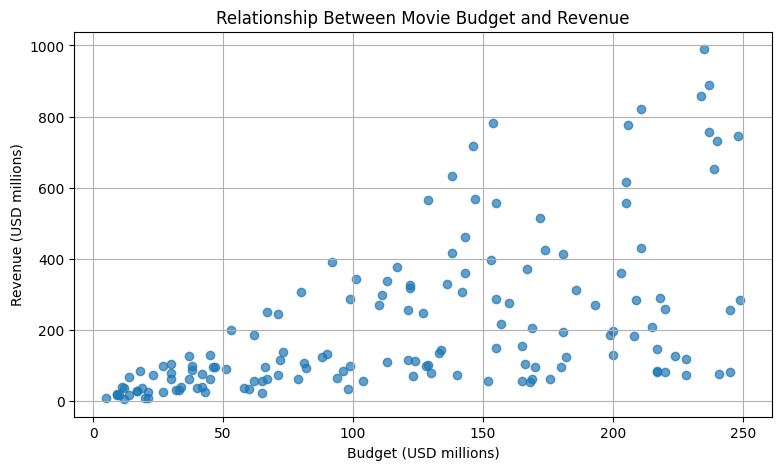

In [15]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df['Budget (USD millions)'],
    df['Revenue (USD millions)'],
    alpha=0.7
)

plt.title("Relationship Between Movie Budget and Revenue")
plt.xlabel("Budget (USD millions)")
plt.ylabel("Revenue (USD millions)")

plt.grid(True)
plt.show()

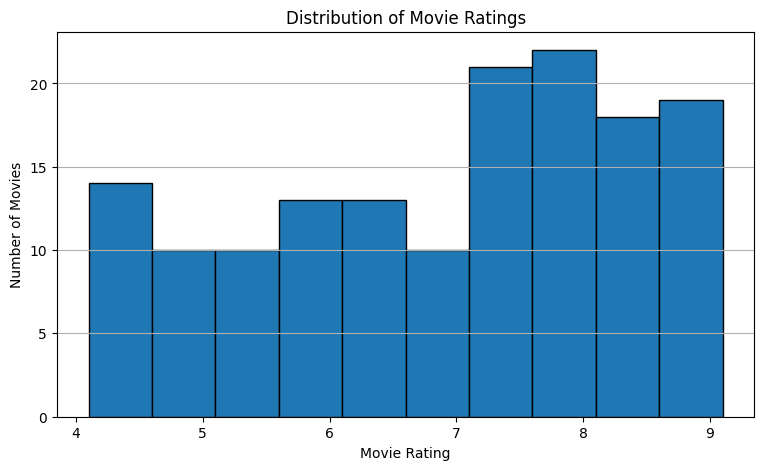

In [16]:
plt.figure(figsize=(9, 5))

plt.hist(
    df['Rating (/10)'],
    bins=10,
    edgecolor='black'
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Movie Rating")
plt.ylabel("Number of Movies")

plt.grid(axis='y')
plt.show()

In [17]:
genre_counts = df['Genre'].value_counts().reset_index()

genre_counts.columns = ['Genre', 'Number of Movies']

genre_revenue = df.groupby('Genre', as_index=False)[
    'Revenue (USD millions)'
].mean()

genre_rating = df.groupby('Genre', as_index=False)[
    'Rating (/10)'
].mean()

print("Dashboard Data Prepared Successfully!")

Dashboard Data Prepared Successfully!


In [18]:
fig1 = px.bar(
    genre_counts,
    x='Genre',
    y='Number of Movies',
    color='Genre',
    title='Movie Distribution Across Genres',
    text='Number of Movies'
)

fig1.update_layout(
    template='plotly_dark',
    xaxis_title='Movie Genre',
    yaxis_title='Number of Movies'
)

fig1.show()

In [19]:
fig2 = px.bar(
    genre_revenue,
    x='Genre',
    y='Revenue (USD millions)',
    color='Genre',
    title=f'{top_genre} Leads in Average Movie Revenue'
)

fig2.update_layout(
    template='plotly_dark',
    xaxis_title='Movie Genre',
    yaxis_title='Average Revenue (USD millions)'
)

fig2.show()

In [20]:
fig3 = px.scatter(
    df,
    x='Budget (USD millions)',
    y='Revenue (USD millions)',
    color='Genre',
    hover_data=['Movie Title', 'Rating (/10)'],
    title=f'Budget vs Revenue (Correlation: {budget_revenue_corr:.2f})'
)

fig3.update_layout(
    template='plotly_dark'
)

fig3.show()

In [21]:
fig4 = px.histogram(
    df,
    x='Rating (/10)',
    nbins=10,
    color='Genre',
    title='Distribution of Movie Ratings',
    barmode='overlay'
)

fig4.update_layout(
    template='plotly_dark',
    xaxis_title='Movie Rating',
    yaxis_title='Number of Movies'
)

fig4.show()

In [22]:
from IPython.display import display, HTML

top_revenue = df['Revenue (USD millions)'].max()
average_rating = df['Rating (/10)'].mean()
average_budget = df['Budget (USD millions)'].mean()

dashboard_header = f"""
<div style="background:#172033; padding:25px;
            border-radius:12px; color:white;
            text-align:center;">

<h1>Movie Entertainment Analytics Dashboard</h1>

<p>Interactive Analysis of 150 Movies</p>

<div style="display:flex; justify-content:space-around;
            flex-wrap:wrap; gap:15px;">

<div>
<h2>{len(df)}</h2>
<p>Total Movies</p>
</div>

<div>
<h2>{df['Genre'].nunique()}</h2>
<p>Total Genres</p>
</div>

<div>
<h2>{average_rating:.2f}/10</h2>
<p>Average Rating</p>
</div>

<div>
<h2>${average_budget:.2f}M</h2>
<p>Average Budget</p>
</div>

</div>
</div>
"""

display(HTML(dashboard_header))

In [23]:
charts = [fig1, fig2, fig3, fig4]

chart_titles = [
    "1. Genre-wise Movie Distribution",
    "2. Average Revenue by Genre",
    "3. Budget vs Revenue Analysis",
    "4. Movie Rating Distribution"
]

html_content = """
<html>
<head>
<title>Movie Entertainment Dashboard</title>
<style>
body {
    background-color: #101827;
    color: white;
    font-family: Arial;
    margin: 20px;
}
h1, h2 {
    text-align: center;
}
.chart {
    background: #172033;
    padding: 15px;
    margin: 20px 0;
    border-radius: 12px;
}
</style>
</head>
<body>

<h1>Movie Entertainment Analytics Dashboard</h1>
<p style="text-align:center;">
Interactive Movie Data Analysis
</p>
"""

html_content += dashboard_header

for i, fig in enumerate(charts):

    chart_html = pio.to_html(
        fig,
        full_html=False,
        include_plotlyjs='cdn' if i == 0 else False
    )

    html_content += f"""
    <div class="chart">
    <h2>{chart_titles[i]}</h2>
    {chart_html}
    </div>
    """

html_content += """
</body>
</html>
"""

with open("Movie_Entertainment_Dashboard.html", "w",
          encoding="utf-8") as file:
    file.write(html_content)

print("Dashboard Exported Successfully!")

Dashboard Exported Successfully!


In [25]:
files.download("Movie_Entertainment_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
top_rating_genre = genre_analysis['Rating (/10)'].idxmax()

if budget_revenue_corr > 0:
    correlation_result = "a positive relationship"
elif budget_revenue_corr < 0:
    correlation_result = "a negative relationship"
else:
    correlation_result = "no linear relationship"

reflection = f"""
This Movie Entertainment Data Analysis project helped in
understanding different aspects of the movie industry.
The dataset contains {len(df)} movies across
{df['Genre'].nunique()} different genres. The analysis revealed
that {top_genre} has the highest average revenue among all
genres, while {top_rating_genre} has the highest average rating.
The correlation between movie budget and revenue is
{budget_revenue_corr:.2f}, indicating {correlation_result}.
Different visualizations helped identify patterns in movie
distribution, revenue generation and audience ratings.
The interactive Plotly dashboard presents these findings
in an organized and user-friendly manner. Overall, this
project improved my understanding of data analysis,
visualization and interactive dashboard development.
"""

print(reflection)


This Movie Entertainment Data Analysis project helped in
understanding different aspects of the movie industry.
The dataset contains 150 movies across
12 different genres. The analysis revealed
that Romance has the highest average revenue among all
genres, while Crime has the highest average rating.
The correlation between movie budget and revenue is
0.57, indicating a positive relationship.
Different visualizations helped identify patterns in movie
distribution, revenue generation and audience ratings.
The interactive Plotly dashboard presents these findings
in an organized and user-friendly manner. Overall, this
project improved my understanding of data analysis,
visualization and interactive dashboard development.

